# Diffusion equation with the forward difference method

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Discretization

Note:
- I put u on a grid: x_i = iΔx, t_n = nΔt and u_i^n = u(x_i, t_n).
- Time derivative: I use the definition of the derivative (Eq. 3.3 in the book), but with a small Δt instead of the limit. This gives the forward difference (Eq. 3.4):

  ∂u/∂t = lim_(Δt -> 0) [u(x, t + Δt) - u(x, t)] / Δt ≈ (u_i^(n+1) - u_i^n) / Δt

- Second derivative: it is the derivative of the first derivative. So I take the forward difference minus the backward difference and divide by Δx. This is the three-point formula (Eq. 3.11), with error O(Δx²):

  ∂²u/∂x² ≈ [(u_(i+1)^n - u_i^n)/Δx - (u_i^n - u_(i-1)^n)/Δx] / Δx = (u_(i+1)^n - 2u_i^n + u_(i-1)^n) / Δx²

- I put both in the diffusion equation and solve for u_i^(n+1) (Eq. 7.90 in the book, the Euler method):

  u_i^(n+1) = u_i^n + γ (u_(i+1)^n - 2u_i^n + u_(i-1)^n), with γ = νΔt/Δx²

- The ends (x = 0 and x = 2.5) have only one neighbour, so I keep u = 1 there.

In [2]:
# One time step of the forward difference method (Eq. 7.90 without source)
# u: u at all grid points at time t_n, gamma = nu*dt/dx^2
# Returns u at time t_(n+1)
def step(u, gamma):
    u_new = u.copy()
    #u[2:] is u_(i+1), u[1:-1] is u_i and u[:-2] is u_(i-1), for all inside points at once
    u_new[1:-1] = u[1:-1] + gamma*(u[2:] - 2*u[1:-1] + u[:-2])
    return u_new #the end points are not changed, so they stay 1

## Setup

Note:
- 51 position steps of Δx = 0.05, so x goes from 0 to 2.5.
- At t = 0: u = 3 for 0.5 ≤ x ≤ 1 and u = 1 everywhere else (u ranges between 1 and 3 m/s).

In [3]:
# Solve the diffusion equation from t = 0
# nu: diffusion coefficient, dt: time step, nt: number of time steps
# Returns the grid x and u after nt time steps
def solve(nu, dt, nt, nx=51, dx=0.05):
    x = np.arange(nx)*dx #x = 0, 0.05, ..., 2.5
    u = np.ones(nx) #u = 1 everywhere
    u[(x >= 0.5) & (x <= 1)] = 3 #u = 3 for 0.5 <= x <= 1
    gamma = nu*dt/dx**2
    for n in range(nt):
        u = step(u, gamma)
    return x, u

## ν between 0.1 and 0.9

I do 151 time steps of Δt = 5·10^-4 (until t = 0.0755) for ν = 0.1, 0.3, 0.5, 0.7 and 0.9.

ν = 0.1: γ = 0.02, u between 1.00 and 2.95
ν = 0.3: γ = 0.06, u between 1.00 and 2.61
ν = 0.5: γ = 0.10, u between 1.00 and 2.37
ν = 0.7: γ = 0.14, u between 1.00 and 2.21
ν = 0.9: γ = 0.18, u between 1.00 and 2.09


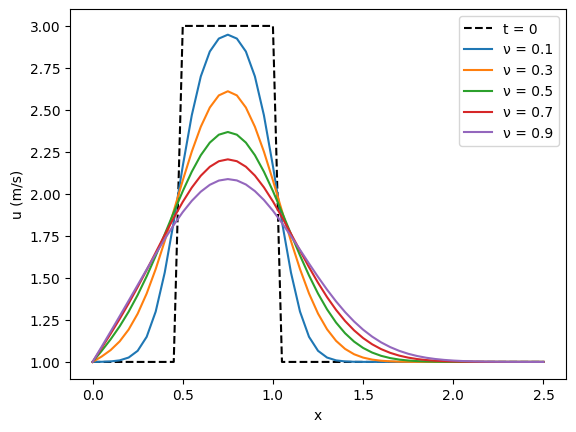

In [4]:
dx, dt, nt = 0.05, 5e-4, 151

fig, ax = plt.subplots()
x, u0 = solve(0.1, dt, 0) #0 time steps, so this is the starting condition
ax.plot(x, u0, 'k--', label='t = 0')
for nu in [0.1, 0.3, 0.5, 0.7, 0.9]:
    x, u = solve(nu, dt, nt)
    ax.plot(x, u, label=f'ν = {nu}')
    print(f"ν = {nu}: γ = {nu*dt/dx**2:.2f}, u between {u.min():.2f} and {u.max():.2f}")
ax.set_xlabel('x'); ax.set_ylabel('u (m/s)'); ax.legend()
plt.show()

Note:
- γ is between 0.02 and 0.18.
- A larger ν diffuses faster, so the peak gets lower and wider.
- u stays between 1 and 3 m/s for every ν, like it should.

## Argument not to use this approach
I take a 10 times larger time step, Δt = 5·10^-3, and compare ν = 0.1 and ν = 0.3.

ν = 0.1: largest |u| = 2.04
ν = 0.3: largest |u| = 6.88e+20


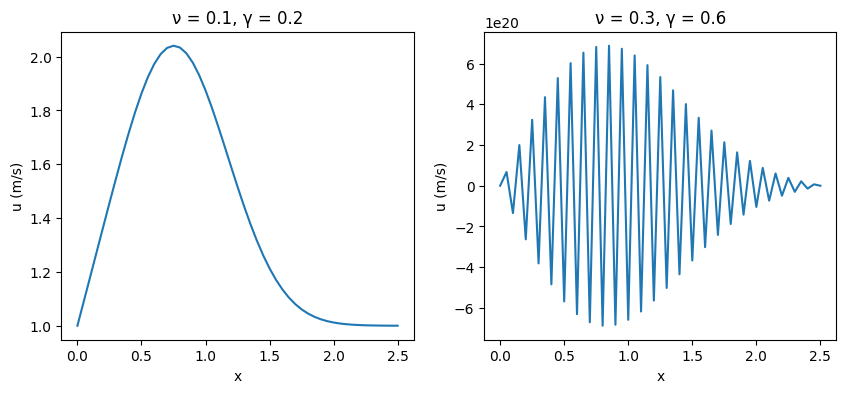

In [5]:
dt_big = 5e-3 #10 times larger time step

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, nu in enumerate([0.1, 0.3]):
    x, u = solve(nu, dt_big, nt)
    ax[k].plot(x, u)
    ax[k].set_title(f'ν = {nu}, γ = {nu*dt_big/dx**2:.1f}')
    ax[k].set_xlabel('x'); ax[k].set_ylabel('u (m/s)')
    print(f"ν = {nu}: largest |u| = {np.abs(u).max():.3g}")
plt.show()

Note:
- For ν = 0.1 the result is still smooth. For ν = 0.3 u blows up: it zig-zags between huge positive and negative values.
- The book says this method is unstable if γ = νΔt/Δx² is larger than 1/2 (section 7.7). So I need Δt ≤ Δx²/(2ν).
- For ν = 0.1 this means Δt ≤ 1.25·10^-2, so Δt = 5·10^-3 is fine (γ = 0.2). For ν = 0.3 it means Δt ≤ 4.2·10^-3, so Δt = 5·10^-3 is too large (γ = 0.6) and u blows up.
- Therefore, the time step is limited by stability, not by accuracy. A larger ν needs a smaller Δt, and if I make Δx 2 times smaller, Δt has to be 4 times smaller. So the method quickly needs very many time steps. That is my argument not to use it.